## Comparisons of all detectors and of the pipeline steps
HW2 (Kaggle **CPU**, no GPU, no Internet; runs in about a minute). Reads only the result files saved by notebooks 02-14
and writes the tables and figures to `/kaggle/working`. A notebook whose output is not attached is skipped with a message.

**What the task asks to compare, and where it is below**
1. Two-stage (02): mAP, AP50, AP_small and inference speed of the configs and the final model.
2. One-stage anchor-based (03): initial and tuned RetinaNet vs the tuned Faster R-CNN.
3. Anchor-free (04): initial and tuned YOLO vs the tuned anchor-based detectors, broken down by object size.
4. Query-based (05): val mAP over training against a CNN detector with the same budget; small objects and dense scenes.
5. Summary of all detector families (official val, speed, leaderboard).
6. Your pipeline: the effect of the inference strategy (model fixed) separately from the effect of model changes
   (inference fixed), then the fusion steps, each with val and leaderboard scores.

**Protocol.** Notebooks 02-05 use the same 5 GroupKFold folds by flight (folds 0 and 1 run; fold 0 only for 05), the same
COCO evaluator (ignored regions as `iscrowd`, up to 500 detections per image) and one check of each final model on the
official val clips (every 5th frame, original resolution). "Tuned" = the config with the best mean CV mAP among the tried ones.
Inference speed is model time per image on a Tesla T4 (all four notebooks ran on a T4).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")
METRICS = ["mAP", "AP50", "AP_s", "AP_m", "AP_l", "ms_per_img"]
SIZE = ["AP_s", "AP_m", "AP_l"]
pd.set_option("display.width", 200)

def find_all(pattern, depth=6):
    # search attached inputs at increasing nesting depth (Kaggle nests inputs differently per source)
    for d in range(depth):
        hit = sorted(INPUT.glob("/".join(["*"] * d + [pattern])))
        if hit:
            return hit
    return []

def read(name, **kw):
    # a result file of one of the notebooks, or None (with a message) if that output is not attached
    hit = find_all(name)
    if not hit:
        print(f"not attached: {name}")
        return None
    return pd.read_csv(hit[0], **kw)

# detector families (notebooks 02-05): cross-validation folds and summaries (cv means + final model on official val)
FAM = {"02": "Faster R-CNN", "03": "RetinaNet", "04": "YOLO11s", "05": "RT-DETR-L"}
FOLDS, SUMM = {}, {}
for k in FAM:
    f, s = read(f"results_{k}_folds.csv"), read(f"results_{k}_summary.csv")
    if f is not None and s is not None:
        FOLDS[k], SUMM[k] = f, s
        for d in (f, s):
            d[METRICS[:-1]] = d[METRICS[:-1]].where(d[METRICS[:-1]] >= 0)      # -1: no ground truth in that size bucket

# (public, private) leaderboard of every submitted file, from the competition's "My submissions" page
LEADERBOARD = {
    "submission_02_faster_rcnn.csv": (0.1964, 0.1566),
    "submission_03_retinanet.csv":   (0.1727, 0.1285),
    "submission_04_yolo11.csv":      (0.2429, 0.1966),
    "submission_05_rtdetr.csv":      (0.0606, 0.0586),
    "submission_07_A2_A3_wbf.csv":   (0.2694, 0.2241),
    "submission_08_A2_A3_wbf.csv":   (0.2393, 0.2200),
    "submission_09_fusion.csv":      (0.2765, 0.2415),
    "submission_10_yolo11m.csv":     (0.2547, 0.2132),
    "submission_10_fusion.csv":      (0.2869, 0.2464),
    "submission_11_ensemble.csv":    (0.2938, 0.2554),
    "submission_12_equal.csv":       (0.2964, 0.2591),
    "submission_14_equal8.csv":      (0.2972, 0.2606),
    "submission_14_no04_08.csv":     (0.2915, 0.2547),
}
print("detector notebooks found:", [FAM[k] for k in FOLDS])

def cv_table(k):
    # mean and std over the CV folds, per config, in the order the configs were tried
    f = FOLDS[k]
    order = list(dict.fromkeys(f.config))
    t = f.groupby("config")[METRICS].agg(["mean", "std"]).loc[order]
    return t

def cv_mean(k):
    f = FOLDS[k]
    return f.groupby("config", sort=False)[METRICS].mean()

def tuned(k):
    return cv_mean(k).mAP.idxmax()

def final_val(k):
    s = SUMM[k]
    return s[s.split == "val"].iloc[0]

detector notebooks found: ['Faster R-CNN', 'RetinaNet', 'YOLO11s', 'RT-DETR-L']


### 1. Two-stage anchor-based: Faster R-CNN (02)

In [2]:
if "02" in FOLDS:
    display(cv_table("02").round(3))
    v = final_val("02")
    print(f"tuned config: {tuned('02')} | final model on official val: mAP {v.mAP:.3f}, AP50 {v.AP50:.3f}, "
          f"AP_small {v.AP_s:.3f}, {v.ms_per_img:.0f} ms per image")

mAP          AP50          AP_s          AP_m          AP_l        ms_per_img       
                       mean    std   mean    std   mean    std   mean    std   mean    std       mean    std
config                                                                                                      
C0_default            0.149  0.026  0.300  0.041  0.052  0.008  0.204  0.004  0.413  0.055     46.022  0.338
C1_anchors_proposals  0.141  0.029  0.312  0.059  0.063  0.017  0.189  0.011  0.359  0.037     55.038  0.141
C2_giou_loss          0.131  0.025  0.304  0.054  0.060  0.014  0.181  0.009  0.328  0.025     55.556  0.302

tuned config: C0_default | final model on official val: mAP 0.164, AP50 0.337, AP_small 0.071, 47 ms per image


**Observations:**
- The default config is the tuned one: CV mAP 0.149 ± 0.026. Data-driven anchors + more proposals (C1) improve AP_small (0.052 -> 0.063) and AP50, but lose large objects (0.413 -> 0.359) and are ~20 % slower (55 vs 46 ms); GIoU (C2) lowers every metric.
- Final model on the official val: mAP 0.164, AP50 0.337, AP_small 0.071, 47 ms per image on a T4. Leaderboard 0.196 public / 0.157 private.

### 2. One-stage anchor-based (RetinaNet, initial and tuned) vs the tuned Faster R-CNN

In [3]:
if {"02", "03"} <= set(FOLDS):
    r = cv_mean("03")
    rows = [("RetinaNet " + c + (" (initial)" if i == 0 else "") + (" (tuned)" if c == tuned("03") else ""), r.loc[c])
            for i, c in enumerate(r.index)]
    rows.append((f"Faster R-CNN {tuned('02')} (tuned)", cv_mean("02").loc[tuned("02")]))
    t = pd.DataFrame({n: s for n, s in rows}).T[METRICS]
    print("cross-validation means (same folds):"); display(t.round(3))
    v = pd.DataFrame({f"{FAM[k]} final ({tuned(k)})": final_val(k)[METRICS] for k in ("02", "03")}).T.astype(float)
    print("final models on the official val:"); display(v.round(3))

cross-validation means (same folds):


,mAP,AP50,AP_s,AP_m,AP_l,ms_per_img
RetinaNet C0_default (initial) (tuned),0.132,0.253,0.026,0.188,0.438,39.997
RetinaNet C1_anchors_iou,0.039,0.128,0.034,0.051,0.030,39.519
RetinaNet C2_giou_loss,0.038,0.128,0.034,0.049,0.026,39.592
Faster R-CNN C0_default (tuned),0.149,0.300,0.052,0.204,0.413,46.022


final models on the official val:


,mAP,AP50,AP_s,AP_m,AP_l,ms_per_img
Faster R-CNN final (C0_default),0.164,0.337,0.071,0.137,0.320,46.525
RetinaNet final (C0_default),0.145,0.280,0.035,0.143,0.299,41.157


**Observations:**
- Initial RetinaNet is below the tuned Faster R-CNN on CV (0.132 vs 0.149) and the tuning attempts made it much worse (0.039 / 0.038, see notebook 03), so the tuned RetinaNet is the default one.
- The gap is mostly small objects: AP_small 0.035 vs 0.071 on the official val (0.026 vs 0.052 in CV), while medium and large objects are about equal. Plausible reasons: Faster R-CNN's FPN starts at stride 4 (RetinaNet at stride 8), and its RoI stage re-samples each proposal at a fixed size, while a one-stage head must classify ~100k dense anchors directly.
- RetinaNet is only ~12 % faster (41 vs 47 ms). Leaderboard: 0.173 / 0.128 vs 0.196 / 0.157 (public / private).

### 3. Anchor-free (YOLO, initial and tuned) vs the tuned anchor-based detectors, by object size

cross-validation means (same folds):


,mAP,AP50,AP_s,AP_m,AP_l,ms_per_img
YOLO11s C0_imgsz640 (initial),0.154,0.291,0.049,0.207,0.421,4.152
YOLO11s C2_imgsz960_lossgains (tuned),0.188,0.360,0.075,0.259,0.437,6.837
RetinaNet C0_default (tuned),0.132,0.253,0.026,0.188,0.438,39.997
Faster R-CNN C0_default (tuned),0.149,0.300,0.052,0.204,0.413,46.022


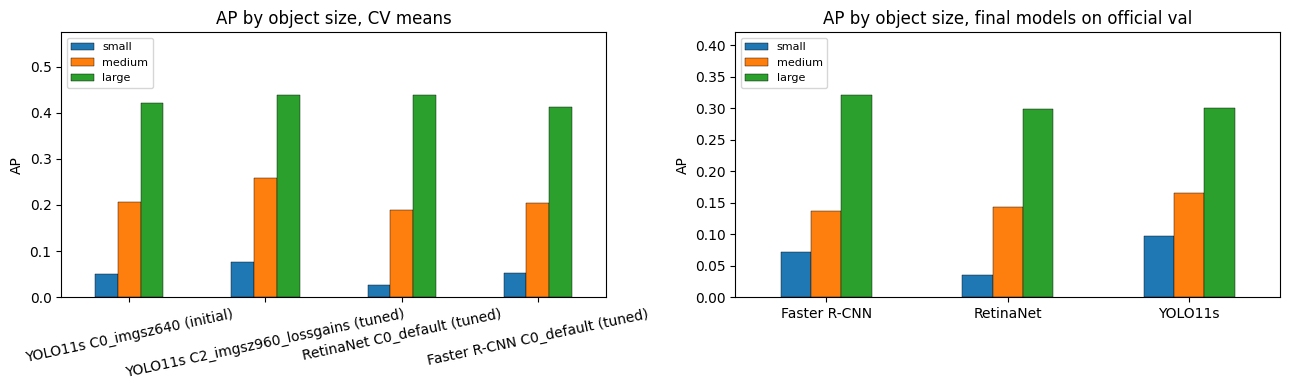

In [4]:
if "04" in FOLDS:
    y = cv_mean("04")
    rows = {f"YOLO11s {y.index[0]} (initial)": y.iloc[0], f"YOLO11s {tuned('04')} (tuned)": y.loc[tuned("04")]}
    for k in ("03", "02"):
        if k in FOLDS:
            rows[f"{FAM[k]} {tuned(k)} (tuned)"] = cv_mean(k).loc[tuned(k)]
    t = pd.DataFrame(rows).T[METRICS]
    print("cross-validation means (same folds):"); display(t.round(3))

    fin = pd.DataFrame({FAM[k]: final_val(k)[METRICS] for k in ("02", "03", "04") if k in SUMM}).T.astype(float)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    t[SIZE].plot.bar(ax=ax[0], rot=12, edgecolor="black", linewidth=0.3)
    ax[0].set(title="AP by object size, CV means", ylabel="AP")
    fin[SIZE].plot.bar(ax=ax[1], rot=0, edgecolor="black", linewidth=0.3)
    ax[1].set(title="AP by object size, final models on official val", ylabel="AP")
    for a in ax:
        a.legend(["small", "medium", "large"], loc="upper left", fontsize=8)
        a.set_ylim(0, a.get_ylim()[1] * 1.25)
    plt.tight_layout(); plt.savefig(WORK / "ap_by_size.png", dpi=120); plt.show()

**Observations:**
- Even the initial YOLO (640 px) beats both tuned anchor-based detectors on CV (0.154 vs 0.149 / 0.132); the tuned YOLO (960 px, higher box / dfl gains) reaches 0.188.
- The gain is entirely small and medium objects: AP_small 0.075 vs 0.052 / 0.026, AP_medium 0.259 vs 0.204 / 0.188, while AP_large is equal (0.41-0.44). On the official val the order is the same for small objects (0.098 vs 0.071 / 0.035), but Faster R-CNN keeps the best AP_large (0.320 vs 0.301).
- YOLO is 6-7x faster (6.8 ms vs 40-46 ms) at a similar training cost per run (~20 min: 8 epochs vs 3 epochs of the torchvision models). Leaderboard 0.243 / 0.197 (public / private), the best single detector.

### 4. Query-based (RT-DETR) vs a CNN detector under the same budget
Same training frames, 8 epochs, 640 px, same held-out fold 0. The curve is Ultralytics' own mAP50-95 on the held-out fold
after each epoch (the CV numbers below use the COCO evaluator of all notebooks, so the two scales differ slightly).

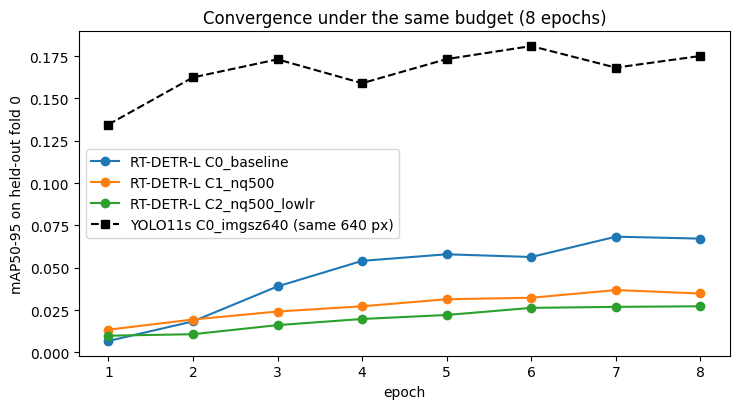

fold 0 (COCO evaluator), training time and GPU memory per run:


,mAP,AP50,AP_s,AP_m,AP_l,ms_per_img,train_min,peak_gb
RT-DETR-L C0_baseline,0.070,0.132,0.031,0.072,0.178,18.733,39.096,6.747
RT-DETR-L C1_nq500,0.040,0.088,0.025,0.050,0.105,20.473,45.386,7.713
RT-DETR-L C2_nq500_lowlr,0.032,0.083,0.024,0.033,0.066,20.310,45.167,7.713
YOLO11s C0_imgsz640,0.167,0.314,0.051,0.208,0.459,4.170,20.922,NaN
YOLO11s C2_imgsz960_lossgains,0.202,0.388,0.084,0.268,0.466,6.831,22.067,3.102


In [5]:
def curve(p):
    d = pd.read_csv(p); d.columns = [c.strip() for c in d.columns]
    return d["epoch"], d["metrics/mAP50-95(B)"]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for p in find_all("curves/rtdetr_C*_f0.csv"):
    ax.plot(*curve(p), marker="o", label="RT-DETR-L " + p.stem.replace("rtdetr_", "").replace("_f0", ""))
yolo = find_all("curves/yolo_C0_imgsz640_f0.csv")
ref = "YOLO11s C0_imgsz640 (same 640 px)"
if not yolo:                                                     # 640 px curve not in 04's output: use its 960 px run
    yolo, ref = find_all("curves/yolo_C1_imgsz960_f0.csv"), "YOLO11s C1_imgsz960 (960 px)"
for p in yolo[:1]:
    ax.plot(*curve(p), marker="s", ls="--", color="black", label=ref)
if not yolo:
    print("no YOLO curve attached (curves/yolo_*_f0.csv from notebook 04)")
ax.set(xlabel="epoch", ylabel="mAP50-95 on held-out fold 0", title="Convergence under the same budget (8 epochs)")
ax.legend(); plt.tight_layout(); plt.savefig(WORK / "convergence.png", dpi=120); plt.show()

if {"04", "05"} <= set(FOLDS):
    cols = METRICS + [c for c in ("train_min", "peak_gb") if c in FOLDS["05"]]
    f0 = {f"RT-DETR-L {c}": g.iloc[0] for c, g in FOLDS["05"][FOLDS["05"].fold == 0].groupby("config", sort=False)}
    y0 = FOLDS["04"][FOLDS["04"].fold == 0].set_index("config")
    for c in ("C0_imgsz640", tuned("04")):
        if c in y0.index:
            f0[f"YOLO11s {c}"] = y0.loc[c]
    print("fold 0 (COCO evaluator), training time and GPU memory per run:")
    display(pd.DataFrame(f0).T[[c for c in cols if c in pd.DataFrame(f0).T]].astype(float).round(3))

**Dense scenes.** RT-DETR returns at most one box per query (300), while YOLO keeps up to 500 boxes per image; the densest
training frame has 180 objects (notebook 01), so 300 queries are enough for the ground truth but leave fewer low-score boxes for recall.

**Observations:**
- **RT-DETR has not converged within the budget.** YOLO11s reaches 0.135 after the first epoch and levels off at ~0.17-0.18 from epoch 3. RT-DETR (300 queries) starts at 0.007 and reaches 0.068 at epoch 7-8, still rising. The 500-query configs learn even slower (0.035 and 0.027 at epoch 8).
- Bipartite matching gives each object one query and needs no NMS, but each object then trains only one prediction per step, which is a plausible reason for the slow start compared with YOLO, where many grid locations per object are positives.
- Small objects: AP_small 0.031 vs 0.051 for YOLO at the same 640 px (fold 0). Costs: ~2x training time per run (39 vs 21 min), 2x GPU memory (6.7 vs 3.1 GB) and 4x inference time (18.7 vs 4.2 ms).
- Leaderboard 0.061 / 0.059 (public / private).

### 5. Summary of all detector families

,config,mAP,AP50,AP_s,AP_m,AP_l,ms_per_img,public LB,private LB
Faster R-CNN,C0_default,0.1637,0.3365,0.0710,0.1366,0.3202,46.5253,0.1964,0.1566
RetinaNet,C0_default,0.1455,0.2798,0.0350,0.1432,0.2990,41.1573,0.1727,0.1285
YOLO11s,C2_imgsz960_lossgains,0.1699,0.3429,0.0976,0.1655,0.3009,7.9346,0.2429,0.1966
RT-DETR-L,C0_baseline,0.0650,0.1268,0.0266,0.0538,0.1520,18.8052,0.0606,0.0586


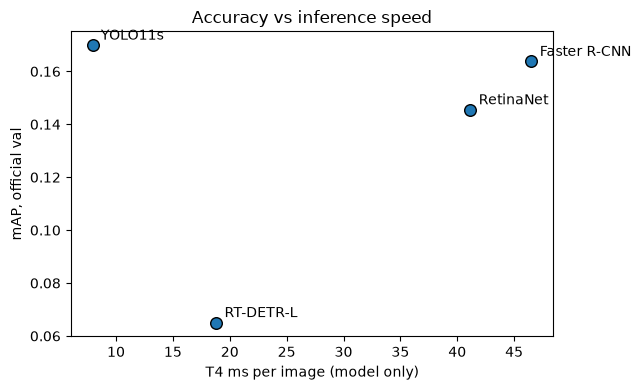

In [6]:
rows = {}
for k in SUMM:
    v = final_val(k)
    sub = {"02": "submission_02_faster_rcnn.csv", "03": "submission_03_retinanet.csv", "04": "submission_04_yolo11.csv",
           "05": "submission_05_rtdetr.csv"}[k]
    rows[FAM[k]] = {"config": tuned(k), **{m: float(v[m]) for m in METRICS},
                    "public LB": LEADERBOARD[sub][0], "private LB": LEADERBOARD[sub][1]}
summary = pd.DataFrame(rows).T
num = [c for c in summary if c != "config"]
summary[num] = summary[num].astype(float)
display(summary.round(4))
summary.to_csv(WORK / "comparison_detectors.csv")

if len(summary):
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.scatter(summary.ms_per_img.astype(float), summary.mAP.astype(float), s=70, edgecolor="black")
    for n, r in summary.iterrows():
        ax.annotate(n, (float(r.ms_per_img), float(r.mAP)), textcoords="offset points", xytext=(6, 4))
    ax.set(xlabel="T4 ms per image (model only)", ylabel="mAP, official val", title="Accuracy vs inference speed")
    plt.tight_layout(); plt.savefig(WORK / "speed_vs_map.png", dpi=120); plt.show()

**Observations:**
- Same ranking on val, public and private leaderboard: YOLO11s (0.170 / 0.243 / 0.197) > Faster R-CNN (0.164 / 0.196 / 0.157) > RetinaNet (0.145 / 0.173 / 0.128) > RT-DETR (0.065 / 0.061 / 0.059).
- YOLO is also the fastest (7.9 ms per image vs 19-47 ms), so it was chosen as the base of the pipeline: its speed leaves room for test-time augmentation and for larger models.
- All CNN detectors lose 0.04-0.05 between the public and the private leaderboard, so the private test clips are harder, not one model overfitting.

### 6. Your pipeline: inference strategy vs model changes vs fusion
**6a. Inference strategy, model fixed** (`final_04`, YOLO11s 960 px; notebook 07). Only the passes and their merging change.

,passes,merge,gain vs S0,mAP,AP50,AP_s,AP_m,AP_l,ms_per_img
strategy,,,,,,,,,
S0_single_pass,full,-,0.0000,0.1699,0.3410,0.0981,0.1661,0.3023,36.4153
A1_upscaled_pass,up,-,0.0063,0.1762,0.3542,0.1124,0.1810,0.2843,18.3949
A2_tta_nms,full+full_flip+up+up_flip,nms,0.0207,0.1906,0.3814,0.1272,0.1914,0.3164,89.1925
A2_tta_wbf,full+full_flip+up+up_flip,wbf,0.0252,0.1951,0.3883,0.1461,0.1959,0.3166,192.0603
A3_tiles_nms,full+tiles,nms,0.0221,0.1919,0.3841,0.1340,0.1921,0.3161,71.0261
A3_tiles_wbf,full+tiles,wbf,0.0216,0.1915,0.3812,0.1341,0.1903,0.3206,123.2820
A2+A3_wbf,full+full_flip+up+up_flip+tiles+tiles_flip,wbf,0.0347,0.2045,0.4058,0.1644,0.2058,0.3279,357.3816


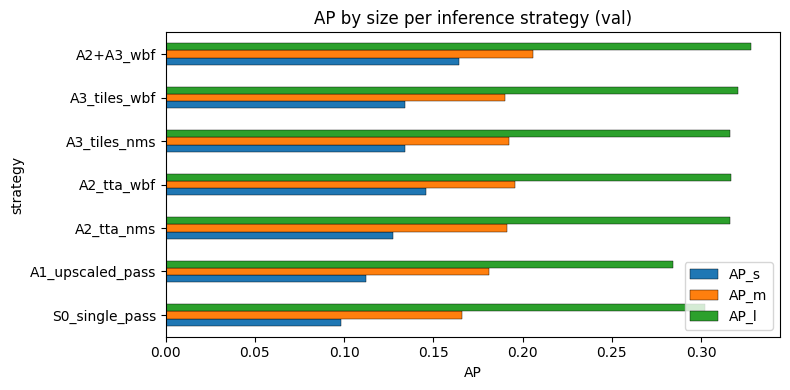

In [7]:
inf = read("results_07_inference.csv", index_col="strategy")
if inf is not None:
    t = inf[["passes", "merge"] + METRICS].copy()
    t.insert(2, "gain vs S0", t.mAP - t.mAP.iloc[0])
    display(t.round(4))
    t[["AP_s", "AP_m", "AP_l"]].plot.barh(figsize=(8, 4), edgecolor="black", linewidth=0.3, title="AP by size per inference strategy (val)")
    plt.xlabel("AP"); plt.tight_layout(); plt.savefig(WORK / "inference_strategies.png", dpi=120); plt.show()

**6b. Model changes, inference fixed.** Every row is one model with the same six-pass inference (`A2+A3_wbf`) on the official
val, so the differences come from the model and its training only. Training changes were first checked on fold 0 (second table).

In [8]:
single, fold0 = [], []
inf = read("results_07_inference.csv", index_col="strategy")
if inf is not None:
    single.append(("final_04: YOLO11s, 960 px, 8 epochs (04)", inf.loc["A2+A3_wbf"]))
s8 = read("results_08_summary.csv")
if s8 is not None:
    single.append(("final_08: YOLO11s, 1280 px, 20 epochs (08)", s8.set_index("config").loc["final_08 A2+A3_wbf"]))
NAMES = {"10": "final_10: YOLO11m, 960 px, 12 epochs (10)", "L960": "YOLO11l, 960 px (11)", "M1280": "YOLO11m, 1280 px (11)",
         "M960b": "YOLO11m, 960 px, seed 1, scale 0.7 (11)", "L960s1": "YOLO11l, 960 px, seed 1 (13)", "L1088": "YOLO11l, 1088 px (13)"}
for f in ("results_10_val.csv", "results_11_val.csv", "results_14_val.csv"):
    d = read(f)
    if d is not None:
        d = d.set_index("variant")
        for k, n in NAMES.items():
            if f"{k} alone" in d.index and n not in [s[0] for s in single]:
                single.append((n, d.loc[f"{k} alone"]))
if single:
    t = pd.DataFrame({n: r[METRICS[:-1]] for n, r in single}).T.astype(float)
    display(t.sort_values("mAP").round(4))

for f, label in (("results_04_folds.csv", "04"), ("results_08_folds.csv", "08"), ("results_10_folds.csv", "10")):
    d = read(f)
    if d is not None:
        for c, g in d[d.fold == 0].groupby("config", sort=False):
            fold0.append({"notebook": label, "config": c, **g[METRICS].iloc[0].to_dict(),
                          **({"train_h": g.train_min.iloc[0] / 60} if "train_min" in g and g.train_min.notna().any() else {})})
if fold0:
    print("training changes on held-out fold 0 (single pass, COCO evaluator):")
    display(pd.DataFrame(fold0).set_index(["notebook", "config"]).round(4))

,mAP,AP50,AP_s,AP_m,AP_l
"final_04: YOLO11s, 960 px, 8 epochs (04)",0.2045,0.4058,0.1644,0.2058,0.3279
"final_08: YOLO11s, 1280 px, 20 epochs (08)",0.2067,0.4162,0.1290,0.2129,0.3078
"YOLO11m, 960 px, seed 1, scale 0.7 (11)",0.2190,0.4327,0.1294,0.2219,0.3221
"final_10: YOLO11m, 960 px, 12 epochs (10)",0.2258,0.4353,0.1450,0.2165,0.3667
"YOLO11l, 960 px, seed 1 (13)",0.2303,0.4415,0.1395,0.2186,0.3825
"YOLO11l, 1088 px (13)",0.2389,0.4580,0.1608,0.2251,0.3745
"YOLO11m, 1280 px (11)",0.2465,0.4869,0.1486,0.2473,0.3741
"YOLO11l, 960 px (11)",0.2531,0.4679,0.1428,0.2261,0.3916


training changes on held-out fold 0 (single pass, COCO evaluator):


mAP    AP50    AP_s    AP_m    AP_l  ms_per_img  train_h
notebook config                                                                            
04       C0_imgsz640            0.1671  0.3138  0.0513  0.2078  0.4594      4.1696   0.3487
         C1_imgsz960            0.2030  0.3836  0.0800  0.2658  0.4741      6.4068   0.0550
         C2_imgsz960_lossgains  0.2018  0.3883  0.0835  0.2678  0.4662      6.8313   0.3678
08       M1_e20_cos             0.1881  0.3623  0.0742  0.2396  0.5071      6.4516   0.7712
         M2_1280_e20_cos        0.1942  0.3826  0.0868  0.2596  0.4481     10.7229   1.2721
10       L1_m960_e12_cos        0.2055  0.3951  0.0884  0.2635  0.5229     13.4938   0.9641

**6c. Fusion steps and leaderboard.** Each submission with its val mAP (the number used to decide) and its leaderboard scores.

,what,val mAP,public LB,private LB
submission,,,,
submission_05_rtdetr.csv,"RT-DETR-L, single pass",0.0650,0.0606,0.0586
submission_07_A2_A3_wbf.csv,YOLO11s (04) + six-pass inference,0.2045,0.2694,0.2241
submission_08_A2_A3_wbf.csv,"YOLO11s 1280 px, 20 epochs + six passes",0.2067,0.2393,0.2200
submission_09_fusion.csv,"fusion of 2 models (04, 08), searched",0.2250,0.2765,0.2415
submission_10_yolo11m.csv,YOLO11m alone (10) + six passes,0.2258,0.2547,0.2132
submission_10_fusion.csv,"fusion of 3 models (+ YOLO11m), searched",0.2469,0.2869,0.2464
submission_11_ensemble.csv,"fusion of 6 models, searched weights",0.2757,0.2938,0.2554
submission_12_equal.csv,"fusion of 6 models, equal weights",0.2701,0.2964,0.2591
submission_14_equal8.csv,"fusion of 8 models, equal weights",0.2721,0.2972,0.2606


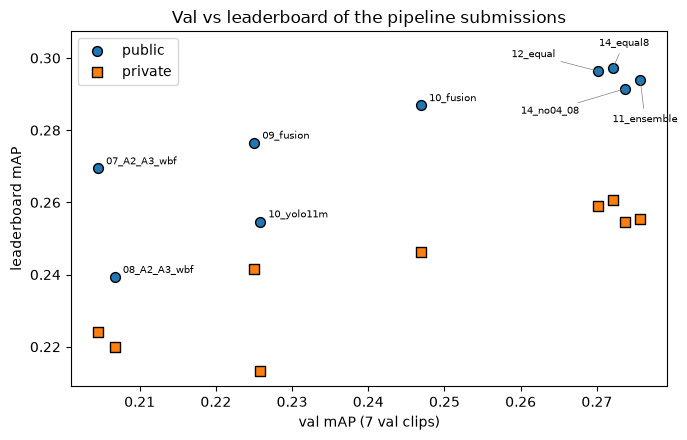

In [9]:
def best_fusion(f):
    d = read(f)
    if d is None:
        return np.nan
    d = d.set_index("variant") if "variant" in d else d
    return d[d.index.str.startswith("fusion ")].mAP.max()

def row(d, key, col="variant"):
    if d is None:
        return np.nan
    d = d.set_index(col)
    return d.loc[key, "mAP"] if key in d.index else np.nan

s5, s8 = read("results_05_summary.csv"), read("results_08_summary.csv")
inf = read("results_07_inference.csv")
steps = [
    ("submission_05_rtdetr.csv",    "RT-DETR-L, single pass",                     s5[s5.split == "val"].mAP.iloc[0] if s5 is not None else np.nan),
    ("submission_07_A2_A3_wbf.csv", "YOLO11s (04) + six-pass inference",          row(inf, "A2+A3_wbf", "strategy")),
    ("submission_08_A2_A3_wbf.csv", "YOLO11s 1280 px, 20 epochs + six passes",    row(s8, "final_08 A2+A3_wbf", "config")),
    ("submission_09_fusion.csv",    "fusion of 2 models (04, 08), searched",      best_fusion("results_09_val.csv")),
    ("submission_10_yolo11m.csv",   "YOLO11m alone (10) + six passes",            row(read("results_10_val.csv"), "10 alone")),
    ("submission_10_fusion.csv",    "fusion of 3 models (+ YOLO11m), searched",   best_fusion("results_10_val.csv")),
    ("submission_11_ensemble.csv",  "fusion of 6 models, searched weights",       best_fusion("results_11_val.csv")),
    ("submission_12_equal.csv",     "fusion of 6 models, equal weights",          row(read("results_12_val.csv"), "equal weights, 6 members")),
    ("submission_14_equal8.csv",    "fusion of 8 models, equal weights",          row(read("results_14_val.csv"), "equal, 8 members")),
    ("submission_14_no04_08.csv",   "fusion of 6 models (8 minus 04, 08), equal", row(read("results_14_val.csv"), "equal, 6 members without 04, 08 (info)")),
]
road = pd.DataFrame([{"submission": f, "what": w, "val mAP": v, "public LB": LEADERBOARD[f][0], "private LB": LEADERBOARD[f][1]}
                     for f, w, v in steps]).set_index("submission")
display(road.round(4))
road.to_csv(WORK / "comparison_pipeline.csv")

r = road[road.index != "submission_05_rtdetr.csv"].dropna(subset=["val mAP", "public LB"])
if len(r):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.scatter(r["val mAP"], r["public LB"], s=50, edgecolor="black", zorder=3, label="public")
    ax.scatter(r["val mAP"], r["private LB"], s=50, marker="s", edgecolor="black", zorder=3, label="private")
    OFFSET = {"12_equal": (-62, 10), "14_equal8": (-10, 16), "14_no04_08": (-75, -18), "11_ensemble": (-20, -30)}   # crowded corner
    for n, x in r.iterrows():
        n = n.replace("submission_", "").replace(".csv", "")
        ax.annotate(n, (x["val mAP"], x["public LB"]), textcoords="offset points", xytext=OFFSET.get(n, (6, 3)), fontsize=7,
                    arrowprops=dict(arrowstyle="-", lw=0.5, color="gray") if n in OFFSET else None)
    ax.set_ylim(top=ax.get_ylim()[1] + 0.006)
    ax.set(xlabel="val mAP (7 val clips)", ylabel="leaderboard mAP", title="Val vs leaderboard of the pipeline submissions")
    ax.legend()
    plt.tight_layout(); plt.savefig(WORK / "val_vs_leaderboard.png", dpi=120); plt.show()

**Observations:**
- **Inference strategy (model fixed):** six passes add +0.035 on val (0.170 -> 0.205), mostly AP_small (0.098 -> 0.164). This gain transferred: leaderboard 0.243 -> 0.269 public and 0.197 -> 0.224 private.
- **Model changes (inference fixed):** larger models are clearly better on val (YOLO11s 0.205 -> YOLO11m 0.226 -> YOLO11l 0.253). Single-model differences on val did not transfer, though: 08 (+0.002 val) lost 0.030 public / 0.004 private, and YOLO11m alone (+0.021 val) scored below YOLO11s with six passes (0.255 / 0.213 vs 0.269 / 0.224). Two YOLO11l seeds differ by 0.023 on val, so single-model differences of this size are mostly noise. (In the fold-0 table, 04's C1 time is evaluation only: its trained weights were reused.)
- **Fusion:** every fusion step improved the private score: 0.224 (one model) -> 0.242 (2 models) -> 0.246 (3) -> 0.255 (6, searched weights) -> 0.259 (6, equal weights) -> **0.261 (8, equal weights; also the best public score, 0.297)**. Combining many models is the most reliable gain of the pipeline.
- **Choices made on val did not transfer:** searched weights (11) were below equal weights (12) on both leaderboards despite +0.006 on val, and leaving out the two weakest members (`14_no04_08`, best val 0.274) lost 0.006 public / 0.006 private. With only 7 val clips, plain equal weights over all members generalise best.
- **Final submission:** `submission_14_equal8.csv` (8-model equal-weight fusion), the best on public and private.